# 03 · Inventory Optimisation

**Decision:** at the start of every week, **how many units of each product should the retailer order?**

Order too little and customers leave empty-handed (**lost margin**). Order too much and cash and warehouse space sit idle (**holding cost**).
Every order also has a fixed **admin and delivery cost**. On top of that, all 5 products share **one warehouse** and **one weekly purchasing budget**.

**This notebook**
1. Sets out the costs and limits
2. Shows what basic theory (the *newsvendor* model) says the right service level is
3. Builds a **mixed-integer linear programme (MILP)** that plans orders for all products 4 weeks ahead
4. **Simulates** 12 real test weeks (mid-Sep to early Dec 2011) with actual demand, comparing the optimiser with simpler policies
5. Tests how the answer changes with **warehouse size**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.stats import norm

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

PRODUCTS = ["Cakestand", "T-Light Holder", "Party Bunting", "Jumbo Bag", "Bird Ornament"]
weekly = pd.read_csv("../data/weekly_demand.csv", parse_dates=["Week"])
DEMAND = weekly.pivot(index="Week", columns="Product", values="Regular")[PRODUCTS]
WEEKS = DEMAND.index
fc = pd.read_csv("../data/forecasts.csv", parse_dates=["Origin", "Week"])
FC = {(o, h, p): f for o, h, p, f in zip(fc["Origin"], fc["Horizon"], fc["Product"], fc["Forecast"])}
REL_SD = pd.read_csv("../data/forecast_uncertainty.csv", index_col=0)["RelErrorStd"][PRODUCTS].values
products = pd.read_csv("../data/products.csv", index_col=0).set_index("Product").loc[PRODUCTS]

def forecast(i, h):
    # Forecast made at the start of week i for week i+h-1 (uses only data before week i)
    return np.array([FC[(WEEKS[i], h, p)] for p in PRODUCTS])

VAL, TEST = range(20, 40), range(40, 52)

## 1. Costs and limits (assumptions)

The dataset has selling prices but not the retailer's costs, so these are **stated assumptions**, typical for gift retail:

| Item | Assumption | Reasoning |
|---|---|---|
| **Purchase cost** | 50% of the selling price | Typical gift-retail gross margin |
| **Holding cost** | 25% of purchase cost per year → ÷ 52 per week | Capital tied up, storage, damage, obsolescence |
| **Stock-out cost** | The lost margin (price − cost) per unit not sold | Unmet demand is lost: customers buy elsewhere |
| **Fixed order cost** | £25 per product per order | Admin, handling, delivery |
| **Warehouse space** | Space per unit (cakestand box = 1.0) and a total capacity of **1,000 space units** ≈ 1.8 weeks of average demand | Larger items take more shelf space |
| **Purchasing budget** | £6,000 per week ≈ 1.5× average weekly purchases | Cash-flow limit |

In [2]:
PRICE = products["TypicalPrice"].values
COST = 0.5 * PRICE
MARGIN = PRICE - COST
HOLD = 0.25 * COST / 52
ORDER_COST = 25.0
SPACE = np.array([1.0, 0.4, 0.1, 0.1, 0.05])     # space units per item
CAPACITY, BUDGET = 1000, 6000

params = pd.DataFrame({"Price £": PRICE, "Cost £": COST, "Margin £ (stock-out cost)": MARGIN,
                       "Holding £/week": HOLD, "Space per unit": SPACE,
                       "Avg weekly demand (test)": DEMAND.iloc[40:52].mean().values}, index=PRODUCTS)
params["Space needed per avg week"] = params["Space per unit"] * params["Avg weekly demand (test)"]
params

,Price £,Cost £,Margin £ (stock-out cost),Holding £/week,Space per unit,Avg weekly demand (test),Space needed per avg week
Cakestand,12.75,6.38,6.38,0.03,1.00,197.42,197.42
T-Light Holder,2.95,1.48,1.48,0.01,0.40,494.75,197.90
Party Bunting,4.95,2.48,2.48,0.01,0.10,153.67,15.37
Jumbo Bag,2.08,1.04,1.04,0.01,0.10,919.83,91.98
Bird Ornament,1.69,0.84,0.84,0.00,0.05,821.33,41.07


In [3]:
print(f"Space needed for one average week of demand: {params['Space needed per avg week'].sum():,.0f} units "
      f"-> capacity {CAPACITY:,} = {CAPACITY / params['Space needed per avg week'].sum():.1f} weeks")

Space needed for one average week of demand: 544 units -> capacity 1,000 = 1.8 weeks


## 2. What does theory say? The newsvendor ratio

For a single product with no other limits, the optimal probability of **not** running out is the **critical ratio**:

$$\text{critical ratio} = \frac{\text{cost of being short by one unit}}{\text{cost of being short} + \text{cost of one unit left over}} = \frac{\text{margin}}{\text{margin} + \text{holding cost per week}}$$

In [4]:
critical_ratio = MARGIN / (MARGIN + HOLD)
Z_NEWSVENDOR = norm.ppf(critical_ratio)
print(f"Critical ratio = {critical_ratio[0]:.4f}  ->  target {critical_ratio[0]:.1%} chance of not running out each week  (z = {Z_NEWSVENDOR[0]:.2f})")
print(f"A lost sale costs {MARGIN[0] / HOLD[0]:.0f}x more than holding a unit for one extra week")

Critical ratio = 0.9952  ->  target 99.5% chance of not running out each week  (z = 2.59)
A lost sale costs 208x more than holding a unit for one extra week


Because a lost sale costs about **200 times** more than holding a unit for a week, theory says **stock up generously** (~99.5% availability).
In reality the **warehouse can't hold that much of everything at once**. The real question is how to **share limited space and budget** across products and weeks.
That is the job of the optimiser.

## 3. The policies we compare

| Policy | Rule each week | Typical of |
|---|---|---|
| **A. Rule of thumb** | Order what you sold last week | Small retailers without forecasting |
| **B. Forecast only** | Order up to the forecast, with no safety buffer | Using forecasts naively |
| **C. Forecast + safety stock** | Order up to forecast × (1 + z × error), with *z* from the newsvendor ratio, product by product | Textbook inventory management |
| **D. MILP optimiser** | Plan 4 weeks ahead for all products together, under space, budget and order costs; implement week 1, re-plan next week | Operations research |

All policies start with the same stock (one week of forecast), face the same real demand, and must respect the warehouse and budget:
if a heuristic's order doesn't fit, it's scaled down proportionally.

## 4. The optimisation model (D)

At the start of week *t*, for every product *p* and planning week *k* = 1…4:

**Decisions**
- $q_{pk}$ = units ordered (delivered at the start of week *k*)
- $y_{pk} \in \{0, 1\}$ = whether an order is placed (binary, for the fixed order cost)

**Expected lost sales.** If $S$ units are available and demand is uncertain (forecast $F$, spread $\sigma$ from notebook 02),
the expected number of units we can't sell is $E[(D - S)^+] = \sigma \cdot L\!\left(\frac{S - F}{\sigma}\right)$, a **convex** curve.
A linear programme can't use the curve directly, but it can use **tangent lines** under it: $e_{pk} \ge a_j S_{pk} + b_j$ for 12 tangent points.
This lets the optimiser **choose its own safety stock** per product, trading margin against space and holding cost.

**Objective:** minimise  $\sum_{p,k}$  holding × expected leftover stock + margin × expected lost sales + £25 × orders placed

**Constraints**
- Stock balance: expected leftover $I_{pk} = I_{p,k-1} + q_{pk} - F_{pk} + e_{pk}$
- Warehouse: $\sum_p \text{space}_p \cdot (I_{p,k-1} + q_{pk}) \le 1{,}000$ every week
- Budget: $\sum_p \text{cost}_p \cdot q_{pk} \le £6{,}000$ every week
- Orders only if placed: $q_{pk} \le M \cdot y_{pk}$

Solved with **HiGHS**, an open-source MILP solver, through SciPy.

In [5]:
TANGENT_Z = np.array([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5])
loss_fn = lambda z: norm.pdf(z) - z * (1 - norm.cdf(z))       # standard normal loss function L(z)

def plan_orders(i, stock0, capacity=CAPACITY, budget=BUDGET, horizon=4, return_plan=False):
    n = len(PRODUCTS)
    hs = [h for h in range(1, horizon + 1) if i + h - 1 < len(WEEKS)]
    T = len(hs)
    F = np.array([forecast(i, h) for h in hs])              # T x n forecasts
    SD = REL_SD * F                                         # T x n uncertainty in units
    idx = lambda block, t, p: block * T * n + t * n + p      # blocks: 0=q, 1=I, 2=e (expected lost), 3=y
    nv = 4 * T * n
    c, integrality, ub = np.zeros(nv), np.zeros(nv), np.full(nv, np.inf)
    A, lo, hi = [], [], []
    big_m = F.sum(axis=0) * 3 + 2000

    for t in range(T):
        for p in range(n):
            c[idx(1, t, p)], c[idx(2, t, p)], c[idx(3, t, p)] = HOLD[p], MARGIN[p], ORDER_COST
            integrality[idx(3, t, p)], ub[idx(3, t, p)] = 1, 1
            # stock balance:  I_t - I_{t-1} - q_t - e_t = -F_t   (I_{-1} = current stock)
            row = np.zeros(nv); row[[idx(1, t, p), idx(0, t, p), idx(2, t, p)]] = [1, -1, -1]
            if t > 0: row[idx(1, t - 1, p)] = -1
            rhs = -F[t, p] + (stock0[p] if t == 0 else 0)
            A.append(row); lo.append(rhs); hi.append(rhs)
            # expected lost sales >= tangent lines of sigma * L((S - F)/sigma), with S = I_{t-1} + q_t
            for z0 in TANGENT_Z:
                slope = 1 - norm.cdf(z0)
                const = SD[t, p] * loss_fn(z0) + slope * (F[t, p] + z0 * SD[t, p])
                row = np.zeros(nv); row[idx(2, t, p)] = 1; row[idx(0, t, p)] = slope
                if t > 0: row[idx(1, t - 1, p)] = slope
                A.append(row); lo.append(const - (slope * stock0[p] if t == 0 else 0)); hi.append(np.inf)
            # q <= M * y
            row = np.zeros(nv); row[idx(0, t, p)] = 1; row[idx(3, t, p)] = -big_m[p]
            A.append(row); lo.append(-np.inf); hi.append(0)
        # warehouse space after delivery
        row, rhs = np.zeros(nv), capacity
        for p in range(n):
            row[idx(0, t, p)] = SPACE[p]
            if t > 0: row[idx(1, t - 1, p)] = SPACE[p]
            else: rhs -= SPACE[p] * stock0[p]
        A.append(row); lo.append(-np.inf); hi.append(rhs)
        # purchasing budget
        row = np.zeros(nv)
        for p in range(n): row[idx(0, t, p)] = COST[p]
        A.append(row); lo.append(-np.inf); hi.append(budget)

    res = milp(c, constraints=LinearConstraint(np.array(A), lo, hi), integrality=integrality,
               bounds=Bounds(np.zeros(nv), ub), options={"disp": False, "time_limit": 20})
    q = res.x[[idx(0, 0, p) for p in range(n)]]
    if return_plan:
        plan = pd.DataFrame(res.x[: T * n].reshape(T, n).round(), columns=PRODUCTS,
                            index=[f"{WEEKS[i + h - 1]:%d %b}" for h in hs])
        return q, plan, F
    return q

## 5. Simulation with real demand

Each simulated week: the policy decides orders using only past information → stock arrives → **real** demand happens →
we sell what we can, unmet demand is lost, leftover stock carries over.

In [6]:
def simulate(policy, weeks, capacity=CAPACITY, budget=BUDGET, z=Z_NEWSVENDOR, record=False):
    weeks = list(weeks)
    stock = forecast(weeks[0], 1).round()            # same starting stock for every policy
    last_sales = DEMAND.iloc[weeks[0] - 1].values.copy()   # "what we sold last week" = last week's actual demand
    totals = dict(holding=0.0, lost_margin=0.0, ordering=0.0, sold=0.0, demand=0.0, stock_value=0.0, orders=0, budget_binding=0)
    log = []
    for i in weeks:
        f1 = forecast(i, 1)
        if policy == "A. Rule of thumb":           q = last_sales.copy()
        elif policy == "B. Forecast only":         q = np.maximum(0, f1 - stock)
        elif policy == "C. Forecast + safety stock": q = np.maximum(0, f1 * (1 + z * REL_SD) - stock)
        else:                                      q = plan_orders(i, stock, capacity, budget)
        # every policy must respect the physical limits
        if SPACE @ (stock + q) > capacity + 1e-6:
            room = max(capacity - SPACE @ stock, 0)
            q = q * room / (SPACE @ q) if SPACE @ q > 0 else q
        if COST @ q > budget:
            q = q * budget / (COST @ q)
        q = np.floor(q + 1e-6)
        totals["budget_binding"] += COST @ q > 0.98 * budget

        available = stock + q
        d = DEMAND.iloc[i].values
        sold = np.minimum(available, d)
        stock = available - sold
        last_sales = sold
        totals["holding"] += HOLD @ stock
        totals["lost_margin"] += MARGIN @ (d - sold)
        totals["ordering"] += ORDER_COST * (q > 0).sum()
        totals["orders"] += int((q > 0).sum())
        totals["sold"] += sold.sum(); totals["demand"] += d.sum()
        totals["stock_value"] += COST @ stock
        if record:
            for p in range(len(PRODUCTS)):
                log.append({"Week": WEEKS[i], "Product": PRODUCTS[p], "Order": q[p], "Available": available[p],
                            "Demand": d[p], "Sold": sold[p], "EndStock": stock[p]})
    out = {"Total cost £": totals["holding"] + totals["lost_margin"] + totals["ordering"],
           "Lost margin £": totals["lost_margin"], "Holding £": totals["holding"], "Ordering £": totals["ordering"],
           "Orders placed": totals["orders"], "Fill rate": totals["sold"] / totals["demand"],
           "Avg stock value £": totals["stock_value"] / len(weeks), "Weeks budget binding": totals["budget_binding"]}
    return (out, pd.DataFrame(log)) if record else out

POLICIES = ["A. Rule of thumb", "B. Forecast only", "C. Forecast + safety stock", "D. MILP optimiser"]

## 6. Check on the validation weeks first

Before touching the test weeks, we confirm on the **validation weeks (late Apr – early Sep)** that the policies behave sensibly.
Nothing is tuned here: the safety factor in policy C comes from theory (the newsvendor ratio), and the optimiser has no tuning knob at all.

In [7]:
val_results = pd.DataFrame({p: simulate(p, VAL) for p in POLICIES}).T
val_results

,Total cost £,Lost margin £,Holding £,Ordering £,Orders placed,Fill rate,Avg stock value £,Weeks budget binding
A. Rule of thumb,"4,189.35","1,349.86",339.50,"2,500.00",100.00,0.97,"3,530.80",3.00
B. Forecast only,"12,841.62","10,397.38",69.24,"2,375.00",95.00,0.85,720.14,1.00
C. Forecast + safety stock,"3,220.68",379.38,341.30,"2,500.00",100.00,0.99,"3,549.49",3.00
D. MILP optimiser,"3,078.93",991.29,462.63,"1,625.00",65.00,0.98,"4,811.39",3.00


## 7. Results on the 12 test weeks (mid-Sep to early Dec 2011)

In [8]:
test_results, logs = {}, {}
for p in POLICIES:
    test_results[p], logs[p] = simulate(p, TEST, record=True)
test_results = pd.DataFrame(test_results).T
test_results

,Total cost £,Lost margin £,Holding £,Ordering £,Orders placed,Fill rate,Avg stock value £,Weeks budget binding
A. Rule of thumb,"2,337.70",649.94,187.77,"1,500.00",60.00,0.98,"3,254.64",0.00
B. Forecast only,"8,759.67","7,353.26",31.42,"1,375.00",55.00,0.83,544.59,0.00
C. Forecast + safety stock,"1,734.28",86.32,197.96,"1,450.00",58.00,1.00,"3,431.27",0.00
D. MILP optimiser,"1,593.72",381.11,237.61,975.00,39.00,0.99,"4,118.62",0.00


In [9]:
base = test_results.loc["A. Rule of thumb", "Total cost £"]
textbook = test_results.loc["C. Forecast + safety stock", "Total cost £"]
best = test_results.loc["D. MILP optimiser", "Total cost £"]
print(f"MILP vs rule of thumb:      {best / base - 1:+.0%} total cost")
print(f"MILP vs textbook (policy C): {best / textbook - 1:+.0%} total cost")
print(f"Validation weeks, MILP vs rule of thumb: "
      f"{val_results.loc['D. MILP optimiser', 'Total cost £'] / val_results.loc['A. Rule of thumb', 'Total cost £'] - 1:+.0%}")

MILP vs rule of thumb:      -32% total cost
MILP vs textbook (policy C): -8% total cost
Validation weeks, MILP vs rule of thumb: -27%


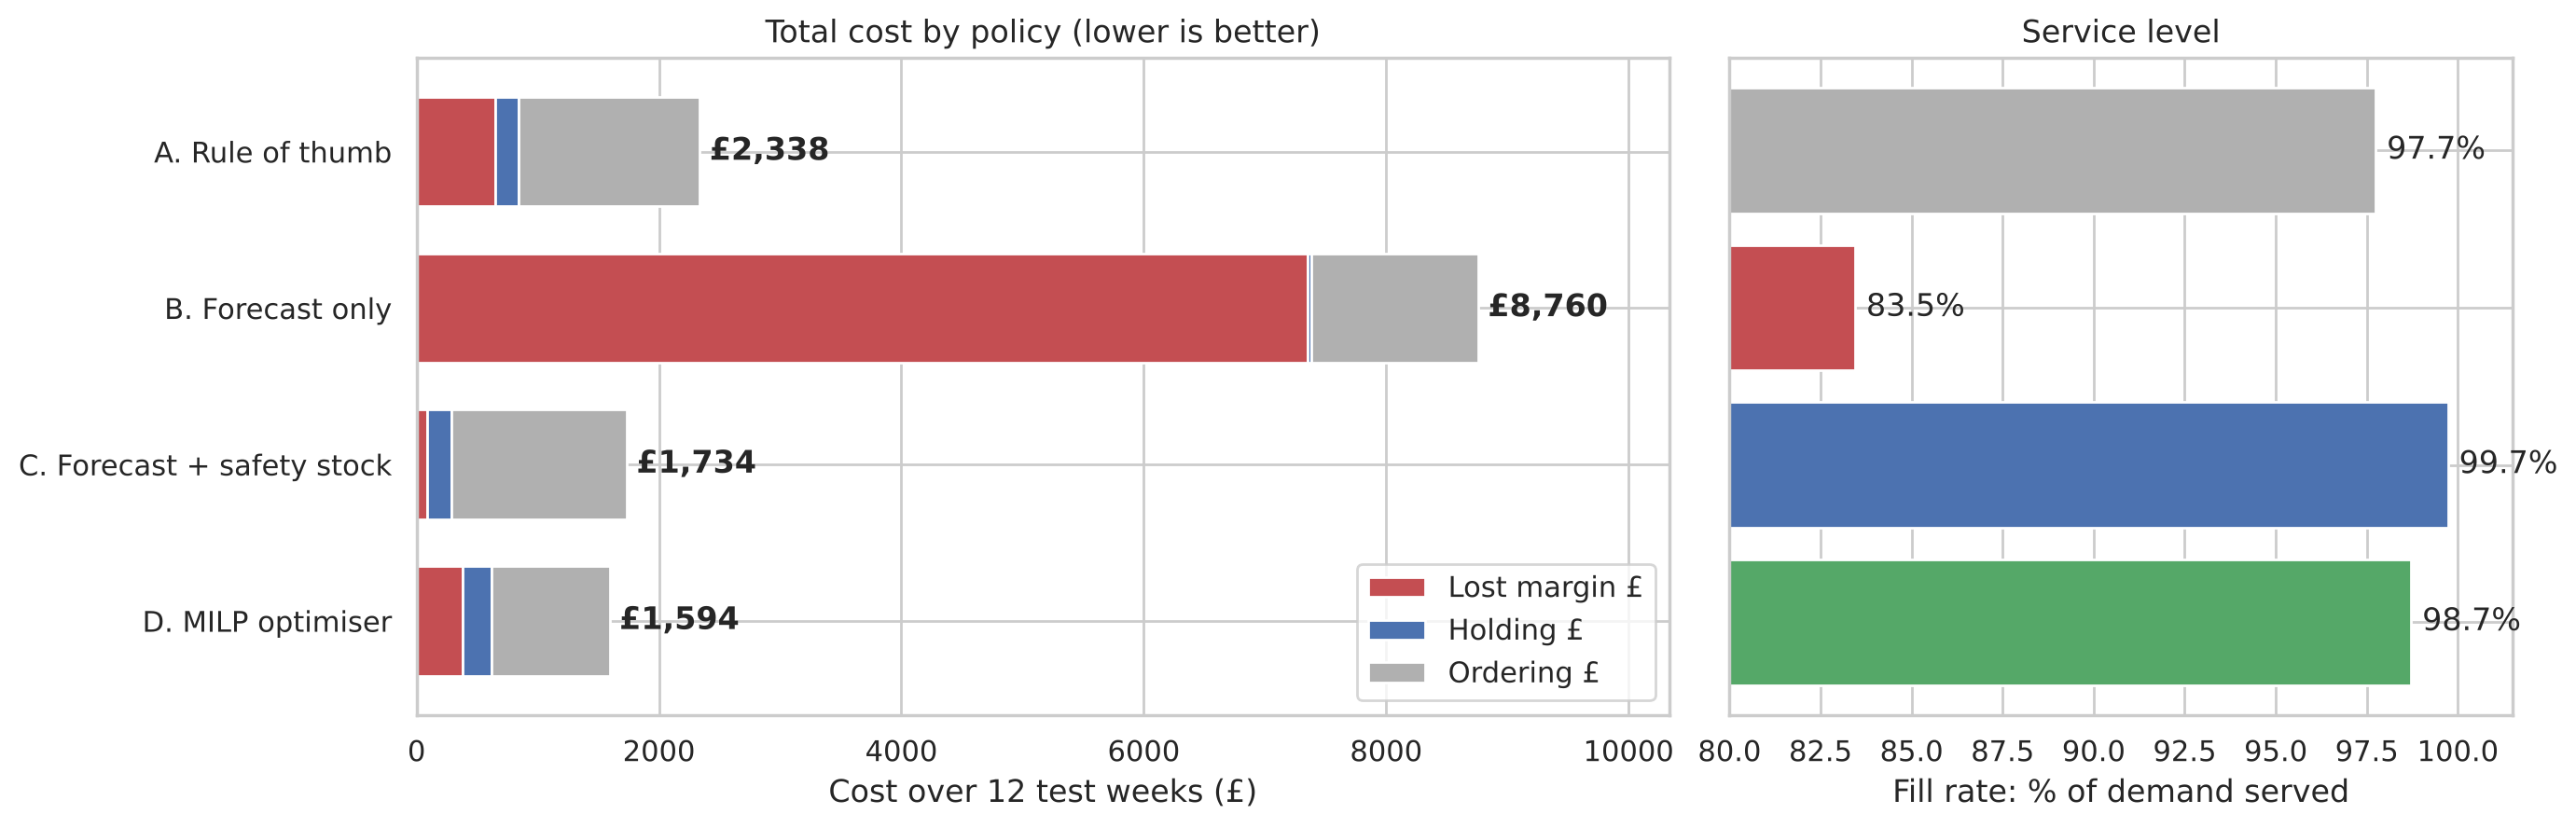

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
parts = test_results[["Lost margin £", "Holding £", "Ordering £"]]
parts.plot.barh(stacked=True, ax=ax1, color=["#C44E52", "#4C72B0", "#B0B0B0"], width=0.7)
for i, total in enumerate(test_results["Total cost £"]):
    ax1.text(total + 80, i, f"£{total:,.0f}", va="center", fontweight="bold")
ax1.invert_yaxis(); ax1.set_xlabel("Cost over 12 test weeks (£)"); ax1.set_ylabel("")
ax1.set_xlim(0, test_results["Total cost £"].max() * 1.18)
ax1.set_title("Total cost by policy (lower is better)")
ax1.legend(loc="lower right")

ax2.barh(test_results.index, test_results["Fill rate"] * 100, color=["#B0B0B0", "#C44E52", "#4C72B0", "#55A868"])
for i, v in enumerate(test_results["Fill rate"] * 100):
    ax2.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax2.set_xlim(80, 101.5); ax2.invert_yaxis(); ax2.set_yticklabels([])
ax2.set_xlabel("Fill rate: % of demand served"); ax2.set_title("Service level")
plt.tight_layout()
plt.savefig("../reports/figures/03_policy_comparison.png", dpi=150)
plt.show()

### What the results show

- **B. Forecast only** is the worst: without a buffer, demand above the forecast is simply lost, about **1 in 6 units**.
  *A good forecast alone isn't enough; you must plan for its error.*
- **A. Rule of thumb** works better than you might expect. "Order what you sold" refills exactly what left the shelf, so it keeps the **total stock constant**
  at its starting level (see section 9). That's a fixed buffer, but it **never adapts** when demand grows, and it orders every product every week.
- **C. Textbook safety stock** reaches very high service, but treats each product separately and still orders weekly.
- **D. The optimiser has the lowest total cost.** Its main advantage is **fewer orders**: it plans 4 weeks ahead, so it batches cheap,
  space-efficient products and orders them less often, while keeping service high.
- The **£6,000 weekly budget** was never the limiting factor in the test weeks; **warehouse space** is what constrains the plan. It deliberately accepts a few more lost sales where protecting them would cost more than it saves.

## 8. Inside the optimiser: one week's plan

In [11]:
i0 = 40
stock0 = forecast(i0, 1).round()
_, plan, F = plan_orders(i0, stock0, return_plan=True)
print(f"Planned orders made on {WEEKS[i0]:%d %b %Y} (only the first row is placed; the rest is re-planned next week):")
plan.astype(int)

Planned orders made on 12 Sep 2011 (only the first row is placed; the rest is re-planned next week):


,Cakestand,T-Light Holder,Party Bunting,Jumbo Bag,Bird Ornament
12 Sep,88,327,525,1432,1872
19 Sep,178,777,0,0,0
26 Sep,229,0,720,1827,0
03 Oct,178,700,0,0,0


Zeros in the plan are deliberate: for small, cheap, compact items it's cheaper to order **two weeks' worth at once** and pay the £25 order cost half as often.
Only week 1 is executed; next week the model re-plans with fresh data (a **rolling horizon**).

## 9. Stock levels over time

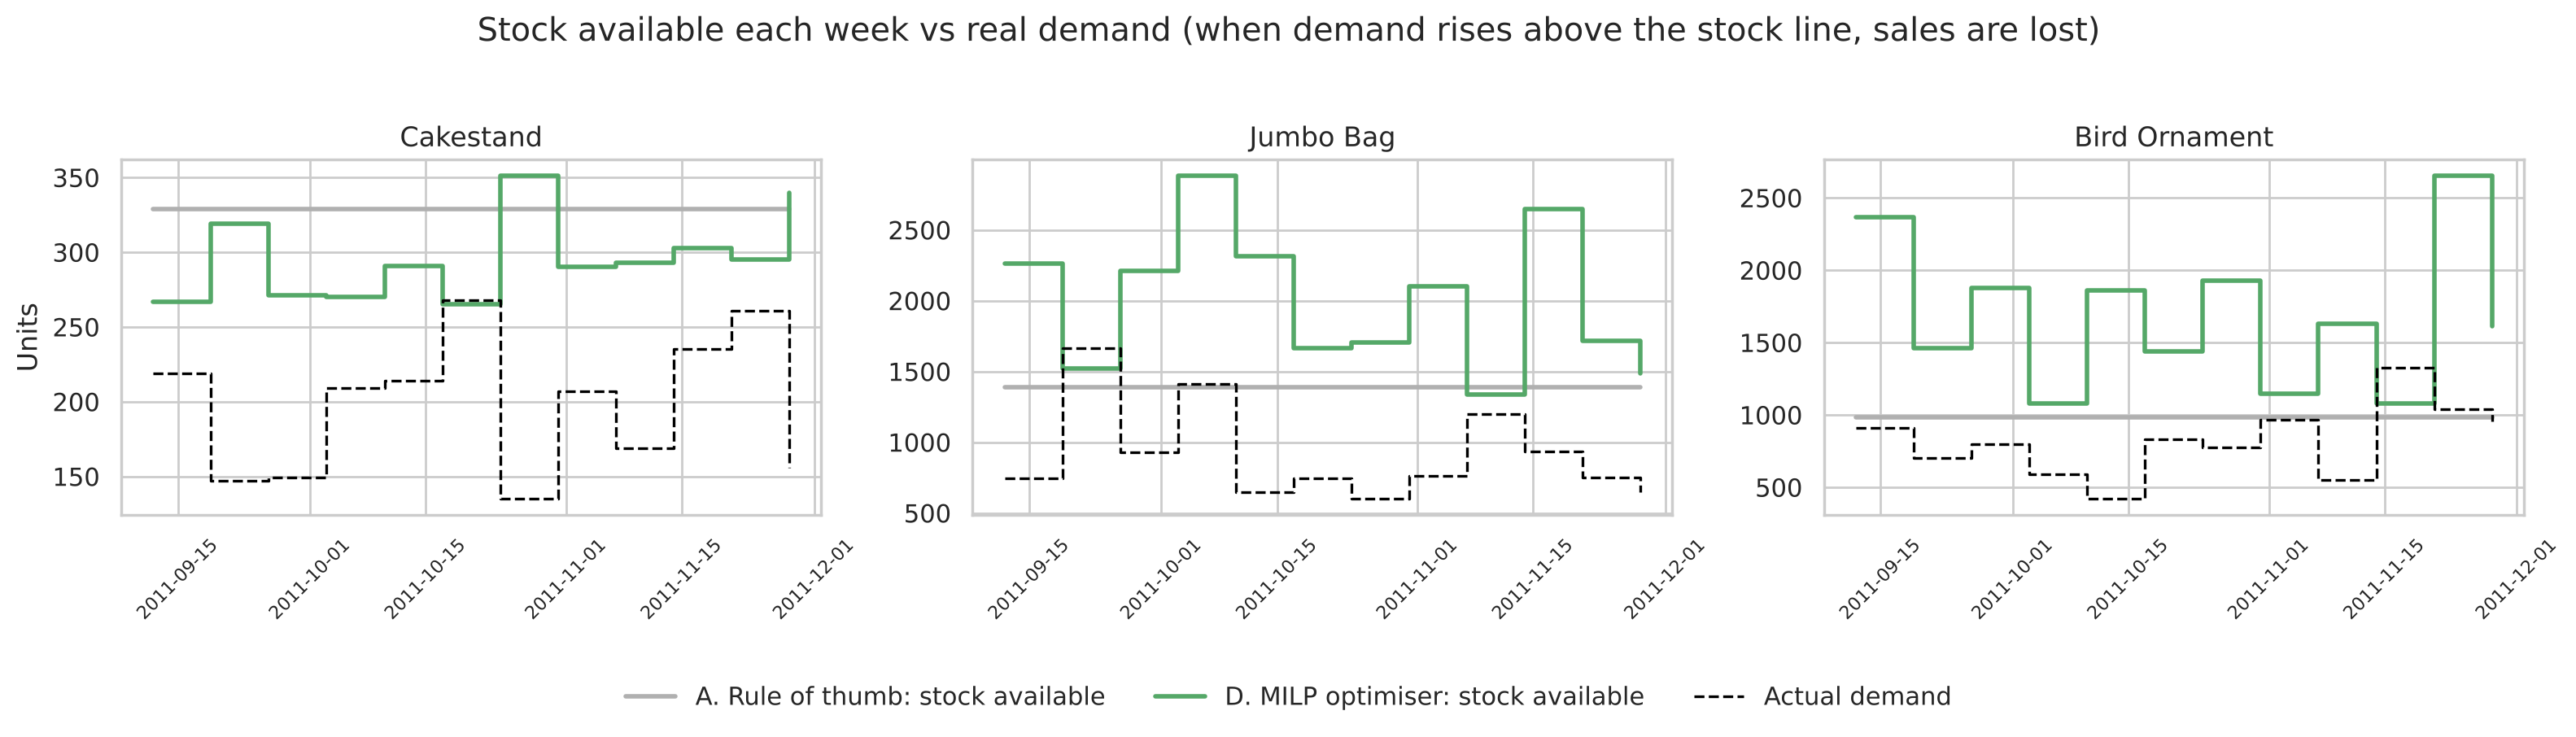

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=False)
for ax, prod in zip(axes, ["Cakestand", "Jumbo Bag", "Bird Ornament"]):
    for pol, col in [("A. Rule of thumb", "#B0B0B0"), ("D. MILP optimiser", "#55A868")]:
        lg = logs[pol][logs[pol]["Product"] == prod]
        ax.step(lg["Week"], lg["Available"], where="post", color=col, lw=2, label=f"{pol}: stock available")
    lg = logs["D. MILP optimiser"][logs["D. MILP optimiser"]["Product"] == prod]
    ax.step(lg["Week"], lg["Demand"], where="post", color="black", lw=1.2, ls="--", label="Actual demand")
    ax.set_title(prod); ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0].set_ylabel("Units")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.13), frameon=False)
fig.suptitle("Stock available each week vs real demand (when demand rises above the stock line, sales are lost)", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/03_stock_levels.png", dpi=150, bbox_inches="tight")
plt.show()

The **rule of thumb's line is flat**: replacing exactly what was sold keeps total stock constant, so it can't respond to the pre-Christmas rise
(look at the Bird Ornament in late November, when demand overtakes it). The optimiser's stock **moves with the forecast**, and the saw-tooth shape is batching:
a large delivery, drawn down over two weeks.

## 10. Sensitivity: how much warehouse space is worth having?

Warehouse capacity is a **strategic decision**: rent more space, or live with stock-outs? We rerun all policies for capacities from 600 to 1,500 space units.

In [13]:
capacities = [600, 700, 800, 900, 1000, 1200, 1500]
sweep = []
for cap in capacities:
    for pol in ["A. Rule of thumb", "C. Forecast + safety stock", "D. MILP optimiser"]:
        r = simulate(pol, TEST, capacity=cap)
        sweep.append({"Capacity": cap, "Policy": pol, "Total cost £": r["Total cost £"], "Fill rate": r["Fill rate"]})
sweep = pd.DataFrame(sweep)
sweep.pivot(index="Capacity", columns="Policy", values="Total cost £").round(0)

Policy,A. Rule of thumb,C. Forecast + safety stock,D. MILP optimiser
Capacity,,,
600,"6,888.00","5,874.00","5,668.00"
700,"4,556.00","3,480.00","3,269.00"
800,"3,125.00","2,314.00","1,975.00"
900,"2,464.00","1,882.00","1,578.00"
1000,"2,338.00","1,734.00","1,594.00"
1200,"2,338.00","1,673.00","1,139.00"
1500,"2,338.00","1,673.00","1,109.00"


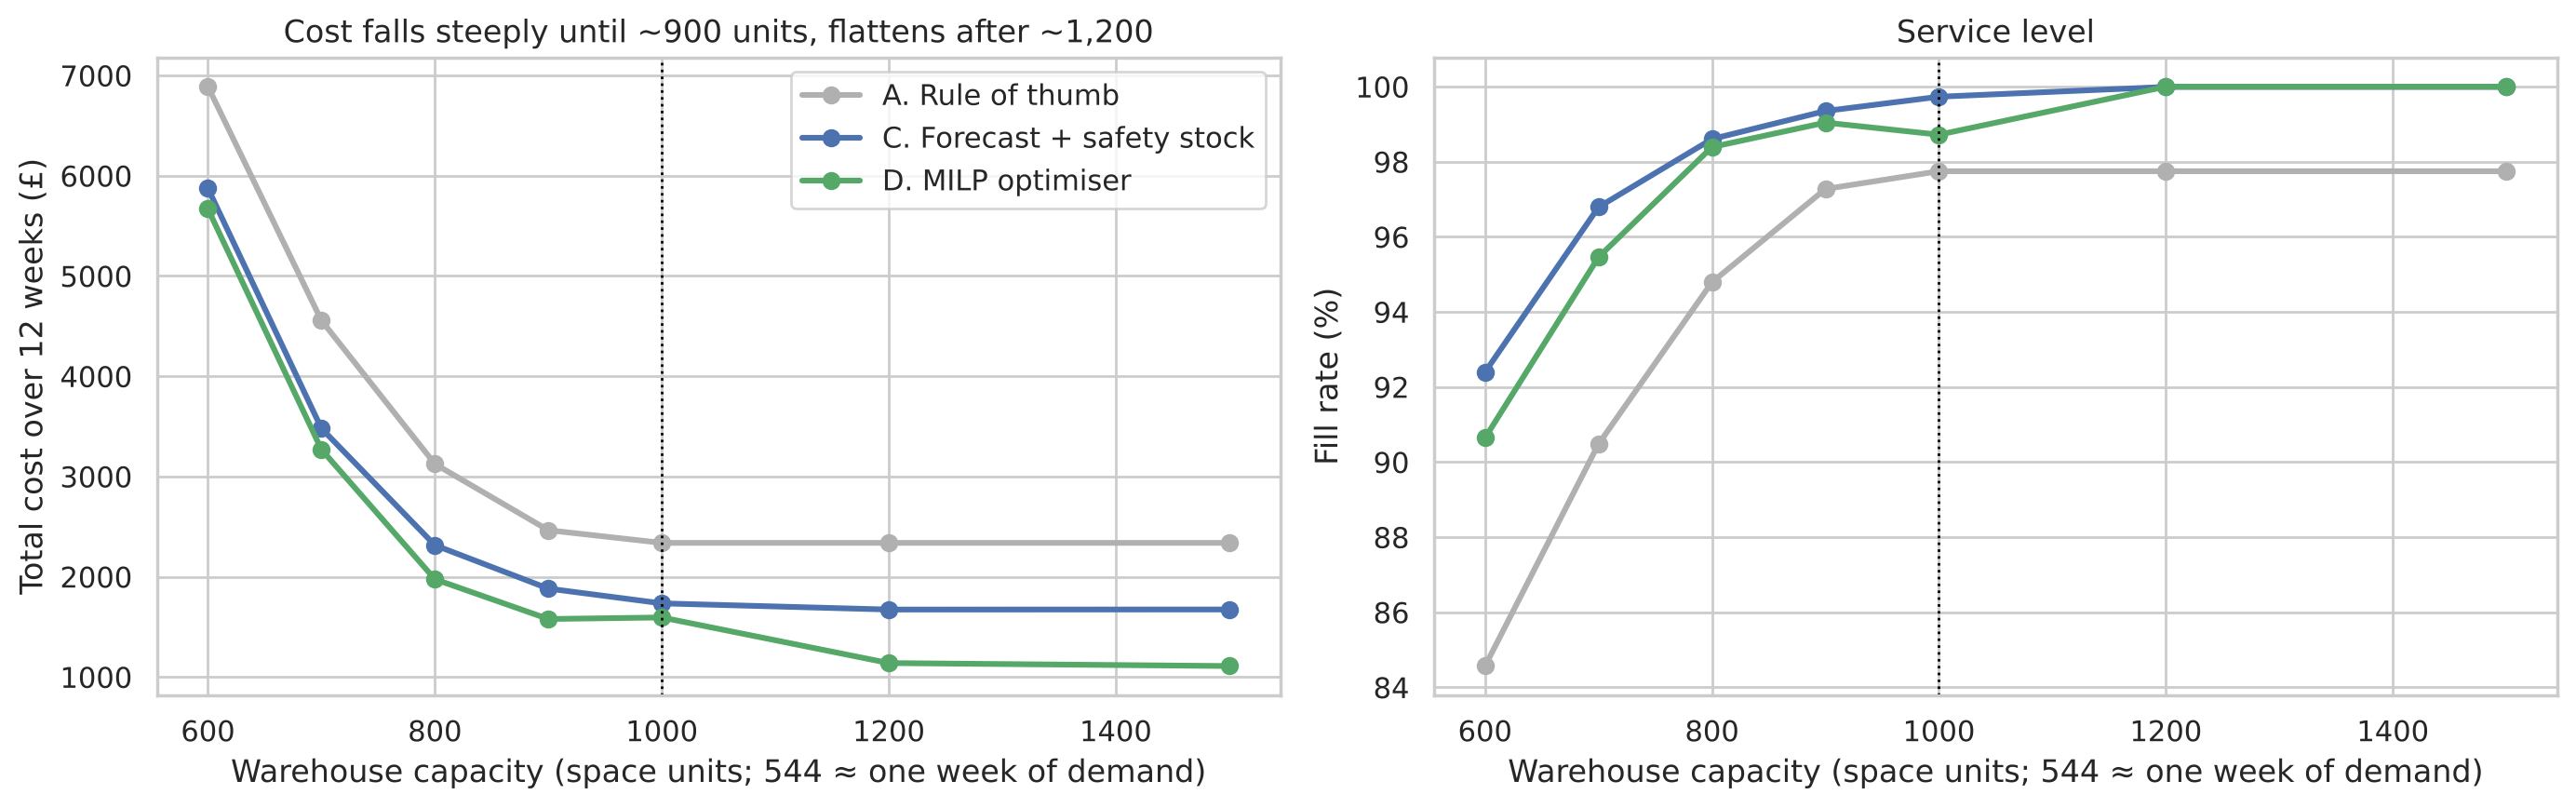

In [14]:
colors = {"A. Rule of thumb": "#B0B0B0", "C. Forecast + safety stock": "#4C72B0", "D. MILP optimiser": "#55A868"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for pol, g in sweep.groupby("Policy"):
    ax1.plot(g["Capacity"], g["Total cost £"], marker="o", lw=2.2, color=colors[pol], label=pol)
    ax2.plot(g["Capacity"], g["Fill rate"] * 100, marker="o", lw=2.2, color=colors[pol], label=pol)
weeks_of_space = params["Space needed per avg week"].sum()
for ax in (ax1, ax2):
    ax.axvline(CAPACITY, color="black", ls=":", lw=1)
    ax.set_xlabel(f"Warehouse capacity (space units; {weeks_of_space:.0f} ≈ one week of demand)")
ax1.set_ylabel("Total cost over 12 weeks (£)"); ax1.set_title("Cost falls steeply until ~900 units, flattens after ~1,200")
ax2.set_ylabel("Fill rate (%)"); ax2.set_title("Service level")
ax1.legend()
plt.tight_layout()
plt.savefig("../reports/figures/03_capacity_sensitivity.png", dpi=150)
plt.show()

- **The optimiser is cheapest at every capacity.** Its advantage doesn't depend on one lucky setting.
- **Space is very valuable when it's tight:** going from 700 to 900 units cuts the optimiser's cost by more than half.
- From ~1,000 to ~1,200 units the optimiser saves another ~£450 (12 weeks): extra room lets it **batch orders** more. Beyond ~1,200 the curve is flat.
- For the **rule of thumb**, extra space beyond ~1,000 is useless: it never orders more than last week's sales.

> **Business question this answers:** *"Should we rent more warehouse space?"* Up to ~900 units, clearly yes.
> Going to ~1,200 saves roughly another £450 per 12 weeks (≈ £2,000 a year) for these 5 products, worth it only if 200 extra space units cost less than that.
> Beyond ~1,200 there's no benefit.

## 11. Limitations

- **Costs are assumptions** (50% margin, 25% annual holding cost, £25 per order, space per unit). With real finance data the numbers change, but the method stays the same.
- **12 test weeks** is a short period, so the £ differences carry uncertainty. The optimiser also had the lowest cost on the 20 validation weeks and at every warehouse size tested, which makes the conclusion more robust.
- Deliveries are assumed to arrive **within the week they're ordered** (short lead time). A longer lead time would need forecasts further ahead and more safety stock.
- **Bulk orders** were excluded and assumed to be handled as advance orders (notebook 01).
- The uncertainty model assumes roughly **normal** forecast errors; real errors are slightly right-skewed (notebook 02).

## Key takeaways

1. **A forecast without a safety buffer fails**: ordering exactly the forecast loses about 1 in 6 units of demand.
2. **Theory (newsvendor) says aim for ~99.5% availability**, because a lost sale costs ~200× a week of holding. The real constraint is **space**.
3. The **MILP optimiser** plans all products 4 weeks ahead under space, budget and order costs, and has the **lowest total cost** of all policies:
   on the test weeks it's ~32% cheaper than the rule of thumb (27% on the validation weeks) and ~8% cheaper than textbook safety stock.
4. Most of its saving comes from **fewer, smarter orders** (batching), not from holding less stock.
5. **Warehouse space has diminishing returns:** expanding to ~900 units clearly pays off, ~1,200 helps the optimiser batch further, and beyond that there's no gain.
6. The **weekly budget of £6,000 never limited** orders in the test weeks (and only in 2–3 validation weeks); **space** is the binding constraint.